# Semaine 3-4 — Training des modèles
### Predictive Maintenance — NASA C-MAPSS (FD001)

Ce notebook entraîne les **4 modèles** demandés par le brief et les sauvegarde dans `models/` pour
évaluation dans un notebook séparé (`Evaluation.ipynb`) :

1. **Régression linéaire** (baseline, rappel de la semaine 2)
2. **XGBoost**
3. **LightGBM**
4. **LSTM** (PyTorch)

**Principe important** : ce notebook ne fait QUE l'entraînement. Toute l'évaluation (métriques, comparaisons,
analyse d'erreurs, calibration) est volontairement dans un notebook séparé — c'est une bonne pratique de
séparer entraînement et évaluation, comme on le ferait avec un `train.py` et un `evaluate.py` en production.


In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
import xgboost as xgb
import lightgbm as lgb
import os

RANDOM_STATE = 42
os.makedirs("models", exist_ok=True)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)


## 1. Chargement des features (semaine 2)

On repart des fichiers `.parquet` générés dans le notebook de feature engineering — pas besoin de refaire
l'EDA ni le feature engineering ici.


In [2]:
train_feat = pd.read_parquet("data/train_features.parquet")
test_feat = pd.read_parquet("data/test_features.parquet")
rul_test = pd.read_parquet("data/rul_test.parquet")

sensor_names = [f"sensor_{i}" for i in range(1, 22)]
WINDOW = 5

# on retrouve la liste des capteurs utiles à partir des colonnes déjà présentes (celles qui ont une
# feature rolling associée sont les capteurs non-constants retenus en semaine 2)
useful_sensors = [s for s in sensor_names if f"{s}_roll_mean{WINDOW}" in train_feat.columns]
feature_cols = (
    useful_sensors
    + [f"{s}_roll_mean{WINDOW}" for s in useful_sensors]
    + [f"{s}_roll_std{WINDOW}" for s in useful_sensors]
)

print(f"{len(useful_sensors)} capteurs utiles, {len(feature_cols)} features au total.")
print("Train:", train_feat.shape, "| Test:", test_feat.shape)


15 capteurs utiles, 45 features au total.
Train: (20631, 57) | Test: (13096, 56)


## 2. Split train / validation (par unité, GroupKFold)

Même méthodologie que la semaine 2 — **identique pour tous les modèles** de ce notebook, afin que la
comparaison entre modèles (faite dans le notebook d'évaluation) soit sur un pied d'égalité.


In [3]:
gkf = GroupKFold(n_splits=5)
groups = train_feat["unit_number"]
train_idx, val_idx = next(gkf.split(train_feat[feature_cols], train_feat["RUL"], groups))

train_df = train_feat.iloc[train_idx].reset_index(drop=True)
val_df = train_feat.iloc[val_idx].reset_index(drop=True)

assert set(train_df["unit_number"]) & set(val_df["unit_number"]) == set(), "Fuite de données détectée !"
print(f"Train: {len(train_df)} lignes / {train_df['unit_number'].nunique()} moteurs")
print(f"Val  : {len(val_df)} lignes / {val_df['unit_number'].nunique()} moteurs")

# on sauvegarde les unités de validation pour que le notebook d'évaluation utilise EXACTEMENT le même split
with open("models/val_units.json", "w") as f:
    json.dump(sorted(val_df["unit_number"].unique().tolist()), f)


Train: 16511 lignes / 80 moteurs
Val  : 4120 lignes / 20 moteurs


## 3. Modèle 1 — Régression linéaire (baseline)

In [4]:
scaler_linreg = StandardScaler()
X_train_lr = scaler_linreg.fit_transform(train_df[feature_cols])
y_train_lr = train_df["RUL"]

linreg = LinearRegression()
linreg.fit(X_train_lr, y_train_lr)

joblib.dump(linreg, "models/linreg.joblib")
joblib.dump(scaler_linreg, "models/linreg_scaler.joblib")
print("Régression linéaire entraînée et sauvegardée.")


Régression linéaire entraînée et sauvegardée.


## 4. Modèle 2 — XGBoost

Early stopping sur le set de validation (unités disjointes du train) pour éviter l'overfitting, plutôt qu'un
nombre d'arbres fixé arbitrairement.


In [5]:
dtrain = xgb.DMatrix(train_df[feature_cols], label=train_df["RUL"])
dval = xgb.DMatrix(val_df[feature_cols], label=val_df["RUL"])

xgb_params = {
    "objective": "reg:squarederror",
    "eval_metric": "rmse",
    "max_depth": 5,
    "eta": 0.05,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "seed": RANDOM_STATE,
}

xgb_model = xgb.train(
    xgb_params,
    dtrain,
    num_boost_round=1000,
    evals=[(dtrain, "train"), (dval, "val")],
    early_stopping_rounds=30,
    verbose_eval=False,
)

xgb_model.save_model("models/xgboost.json")
print(f"XGBoost entraîné — meilleure itération : {xgb_model.best_iteration} "
      f"(best val RMSE: {xgb_model.best_score:.2f})")


XGBoost entraîné — meilleure itération : 80 (best val RMSE: 18.41)


## 5. Modèle 3 — LightGBM

Même logique d'early stopping, hyperparamètres de départ volontairement proches de ceux de XGBoost pour que
la comparaison porte sur l'algorithme et pas sur un tuning déséquilibré entre les deux.


In [6]:
lgb_train = lgb.Dataset(train_df[feature_cols], label=train_df["RUL"])
lgb_val = lgb.Dataset(val_df[feature_cols], label=val_df["RUL"], reference=lgb_train)

lgb_params = {
    "objective": "regression",
    "metric": "rmse",
    "max_depth": 5,
    "learning_rate": 0.05,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "seed": RANDOM_STATE,
    "verbose": -1,
}

lgb_model = lgb.train(
    lgb_params,
    lgb_train,
    num_boost_round=1000,
    valid_sets=[lgb_val],
    callbacks=[lgb.early_stopping(stopping_rounds=30, verbose=False)],
)

lgb_model.save_model("models/lightgbm.txt")
print(f"LightGBM entraîné — meilleure itération : {lgb_model.best_iteration}")


LightGBM entraîné — meilleure itération : 100


## 6. Modèle 4 — LSTM (PyTorch)

Contrairement aux modèles précédents (qui voient une ligne = un instant t, indépendamment des autres), le
LSTM voit une **séquence** de cycles consécutifs et doit apprendre lui-même la dynamique temporelle.

**Construction des séquences** :
- Fenêtre de longueur fixe `SEQ_LEN` (ici 30 cycles).
- Pour un moteur ayant moins de `SEQ_LEN` cycles disponibles, on complète (« padding ») en répétant la
  première ligne — c'est une approche standard sur C-MAPSS, à documenter dans le rapport comme un choix
  parmi d'autres (le zero-padding est une alternative, mais moins physique ici).
- Pour l'entraînement, on génère une séquence **par cycle** de chaque moteur (fenêtre glissante), ce qui
  démultiplie les exemples d'entraînement.


In [7]:
SEQ_LEN = 30
lstm_features = useful_sensors  # on utilise les capteurs bruts : le LSTM apprend lui-même la dynamique temporelle

def build_sequences(df, feature_list, seq_len, group_col="unit_number", time_col="time_in_cycles", target_col="RUL"):
    """Construit un exemple (séquence, target) par cycle de chaque moteur (fenêtre glissante causale)."""
    sequences, targets, meta = [], [], []
    for unit, unit_df in df.sort_values(time_col).groupby(group_col):
        values = unit_df[feature_list].values
        rul_values = unit_df[target_col].values if target_col in unit_df.columns else None
        cycles = unit_df[time_col].values
        n = len(unit_df)
        for i in range(n):
            start = max(0, i - seq_len + 1)
            window = values[start:i + 1]
            if len(window) < seq_len:
                pad = np.repeat(window[0:1], seq_len - len(window), axis=0)
                window = np.concatenate([pad, window], axis=0)
            sequences.append(window)
            if rul_values is not None:
                targets.append(rul_values[i])
            meta.append((unit, cycles[i]))
    X = np.stack(sequences).astype(np.float32)
    y = np.array(targets, dtype=np.float32) if targets else None
    return X, y, meta


In [8]:
# scaling fit UNIQUEMENT sur le train (comme pour les autres modèles)
scaler_lstm = StandardScaler()
scaler_lstm.fit(train_df[lstm_features])

def scale_df(df, scaler, features):
    df = df.copy()
    df[features] = scaler.transform(df[features])
    return df

train_scaled = scale_df(train_df, scaler_lstm, lstm_features)
val_scaled = scale_df(val_df, scaler_lstm, lstm_features)

X_train_seq, y_train_seq, _ = build_sequences(train_scaled, lstm_features, SEQ_LEN)
X_val_seq, y_val_seq, _ = build_sequences(val_scaled, lstm_features, SEQ_LEN)

print("Train séquences:", X_train_seq.shape, "| Val séquences:", X_val_seq.shape)


Train séquences: (16511, 30, 15) | Val séquences: (4120, 30, 15)


In [9]:
class RULDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)
        self.y = torch.from_numpy(y)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


class LSTMRegressor(nn.Module):
    def __init__(self, n_features, hidden_size=64, num_layers=1, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.head = nn.Sequential(
            nn.Linear(hidden_size, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        out, (h_n, _) = self.lstm(x)
        last_hidden = h_n[-1]  # dernier état caché de la dernière couche
        return self.head(last_hidden).squeeze(-1)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cpu


In [10]:
BATCH_SIZE = 256
N_EPOCHS = 15
LEARNING_RATE = 1e-3

train_loader = DataLoader(RULDataset(X_train_seq, y_train_seq), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(RULDataset(X_val_seq, y_val_seq), batch_size=BATCH_SIZE, shuffle=False)

lstm_model = LSTMRegressor(n_features=len(lstm_features)).to(device)
optimizer = torch.optim.Adam(lstm_model.parameters(), lr=LEARNING_RATE)
criterion = nn.MSELoss()

history = {"train_loss": [], "val_loss": []}
best_val_rmse = float("inf")

for epoch in range(1, N_EPOCHS + 1):
    lstm_model.train()
    train_losses = []
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        pred = lstm_model(xb)
        loss = criterion(pred, yb)
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())

    lstm_model.eval()
    val_losses = []
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            pred = lstm_model(xb)
            val_losses.append(criterion(pred, yb).item())

    train_rmse = float(np.sqrt(np.mean(train_losses)))
    val_rmse = float(np.sqrt(np.mean(val_losses)))
    history["train_loss"].append(train_rmse)
    history["val_loss"].append(val_rmse)
    print(f"Epoch {epoch:2d}/{N_EPOCHS} — train RMSE: {train_rmse:.2f} | val RMSE: {val_rmse:.2f}")

    if val_rmse < best_val_rmse:
        best_val_rmse = val_rmse
        torch.save(lstm_model.state_dict(), "models/lstm_best.pt")

print(f"\nMeilleur val RMSE (early-stopping manuel) : {best_val_rmse:.2f}")


Epoch  1/15 — train RMSE: 93.44 | val RMSE: 83.93


Epoch  2/15 — train RMSE: 74.46 | val RMSE: 58.09


Epoch  3/15 — train RMSE: 46.96 | val RMSE: 32.17


Epoch  4/15 — train RMSE: 27.30 | val RMSE: 19.70


Epoch  5/15 — train RMSE: 20.70 | val RMSE: 16.69


Epoch  6/15 — train RMSE: 18.27 | val RMSE: 16.34


... (5 outputs left out)

Epoch 12/15 — train RMSE: 16.55 | val RMSE: 14.33


Epoch 13/15 — train RMSE: 16.34 | val RMSE: 13.22


Epoch 14/15 — train RMSE: 16.37 | val RMSE: 14.47


Epoch 15/15 — train RMSE: 16.21 | val RMSE: 13.80

Meilleur val RMSE (early-stopping manuel) : 13.22


**Point d'attention à documenter dans le rapport** : contrairement à XGBoost/LightGBM qui ont un
early stopping automatique intégré, ici on sauvegarde manuellement le meilleur modèle observé sur la
validation à chaque epoch (`models/lstm_best.pt`), plutôt que le modèle de la dernière epoch — c'est
l'équivalent "fait main" du early stopping pour PyTorch.


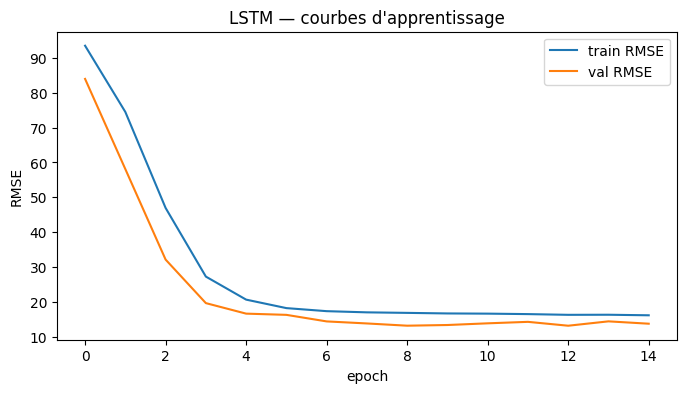

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(history["train_loss"], label="train RMSE")
plt.plot(history["val_loss"], label="val RMSE")
plt.xlabel("epoch")
plt.ylabel("RMSE")
plt.title("LSTM — courbes d'apprentissage")
plt.legend()
plt.show()


In [12]:
# on sauvegarde aussi le scaler et la config, nécessaires pour recharger le modèle dans l'évaluation
joblib.dump(scaler_lstm, "models/lstm_scaler.joblib")
with open("models/lstm_config.json", "w") as f:
    json.dump({
        "seq_len": SEQ_LEN,
        "features": lstm_features,
        "hidden_size": 64,
        "num_layers": 1,
        "dropout": 0.2,
    }, f)

print("LSTM sauvegardé : models/lstm_best.pt, models/lstm_scaler.joblib, models/lstm_config.json")


LSTM sauvegardé : models/lstm_best.pt, models/lstm_scaler.joblib, models/lstm_config.json


## 7. Récapitulatif des artefacts sauvegardés

| Modèle | Fichier(s) |
|---|---|
| Régression linéaire | `models/linreg.joblib`, `models/linreg_scaler.joblib` |
| XGBoost | `models/xgboost.json` |
| LightGBM | `models/lightgbm.txt` |
| LSTM | `models/lstm_best.pt`, `models/lstm_scaler.joblib`, `models/lstm_config.json` |
| Split de validation (pour reproductibilité) | `models/val_units.json` |

**Prochaine étape** : ouvrir `Evaluation.ipynb`, qui recharge ces 4 modèles et effectue toute l'analyse
comparative (RMSE/MAE, évaluation par unité, calibration, fonction de scoring asymétrique, analyse
d'erreurs).
